## **Tugas 3-WEB SCRAPPING**

In [1]:
import requests
from bs4 import BeautifulSoup

In [2]:
app_id = 413150  # ini id nya menyesuaikan game yg dipilih

url = f'https://store.steampowered.com/app/{app_id}/'
page = requests.get(url, cookies={'birthtime':'568022401'})
# cookie 'birthtime' buat lewatin age-check klo gamenya ada rating dewasa
page

<Response [200]>

Pada bagian ini kita menentukan ID game yang akan diambil dari Steam. Karena game yang dipilih adalah Stardew Valley, maka digunakan app_id = 413150. Setelah itu, URL Steam dibuat berdasarkan ID tersebut dan halaman game diakses menggunakan requests. Cookie birthtime digunakan untuk melewati age-check apabila halaman game memerlukannya.

In [3]:
soup = BeautifulSoup(page.text, 'html.parser')
soup

<!DOCTYPE html>

<html class="responsive DesktopUI" lang="en">
<head>
<meta content="text/html; charset=utf-8" http-equiv="Content-Type"/>
<meta content="width=device-width,initial-scale=1" name="viewport"/>
<meta content="#171a21" name="theme-color"/>
<title>Stardew Valley on Steam</title>
<link href="/favicon.ico" rel="shortcut icon" type="image/x-icon"/>
<link href="https://store.akamai.steamstatic.com/public/shared/css/motiva_sans.css?v=4Vj7bvhvv_UL&amp;l=english&amp;_cdn=akamai" rel="stylesheet" type="text/css"/>
<link href="https://store.akamai.steamstatic.com/public/shared/css/shared_global.css?v=6XGwIQA5VRXI&amp;l=english&amp;_cdn=akamai" rel="stylesheet" type="text/css"/>
<link href="https://store.akamai.steamstatic.com/public/shared/css/buttons.css?v=u7ItYmj40jWH&amp;l=english&amp;_cdn=akamai" rel="stylesheet" type="text/css"/>
<link href="https://store.akamai.steamstatic.com/public/css/v6/store.css?v=b2kk9Hj3eEuj&amp;l=english&amp;_cdn=akamai" rel="stylesheet" type="text/css

Di bagian ini kita mengambil isi halaman Steam yang sudah diakses sebelumnya, kemudian menggunakan BeautifulSoup untuk membaca dan mengambil elemen HTML tertentu dari halaman tersebut.

In [4]:
soup.title

<title>Stardew Valley on Steam</title>

In [5]:
soup.find('div', {'id':'appHubAppName'})

<div aria-level="1" class="apphub_AppName" id="appHubAppName" role="heading">Stardew Valley</div>

In [6]:
soup.find('div', {'id':'appHubAppName'}).text

'Stardew Valley'

In [7]:
soup.find('div', {'id':'game_area_description'}).text

"\nAbout This Game\n\t\t\t\t\t\t\tStardew Valley is an open-ended country-life RPG!  You've inherited your grandfather's old farm plot in Stardew Valley. Armed with hand-me-down tools and a few coins, you set out to begin your new life. Can you learn to live off the land and turn these overgrown fields into a thriving home? It won't be easy. Ever since Joja Corporation came to town, the old ways of life have all but disappeared. The community center, once the town's most vibrant hub of activity, now lies in shambles. But the valley seems full of opportunity. With a little dedication, you might just be the one to restore Stardew Valley to greatness!Features Turn your overgrown field into a lively farm!   Raise animals, grow crops, start an orchard, craft useful machines, and more! You'll have plenty of space to create the farm of your dreams. 8 Player Farming! Invite 1-7 players to join you in the valley online! Players can work together to build a thriving farm, share resources, and im

In [8]:
soup.find('div', {'class':'glance_tags popular_tags'})

<div class="glance_tags popular_tags" data-appid="413150" data-panel='{"flow-children":"row"}'>
<a class="app_tag" href="https://store.steampowered.com/tags/en/Farming%20Sim/?snr=1_5_9__409" style="display: none;">
												Farming Sim												</a><a class="app_tag" href="https://store.steampowered.com/tags/en/Pixel%20Graphics/?snr=1_5_9__409" style="display: none;">
												Pixel Graphics												</a><a class="app_tag" href="https://store.steampowered.com/tags/en/Multiplayer/?snr=1_5_9__409" style="display: none;">
												Multiplayer												</a><a class="app_tag" href="https://store.steampowered.com/tags/en/Life%20Sim/?snr=1_5_9__409" style="display: none;">
												Life Sim												</a><a class="app_tag" href="https://store.steampowered.com/tags/en/RPG/?snr=1_5_9__409" style="display: none;">
												RPG												</a><a class="app_tag" href="https://store.steampowered.com/tags/en/Relaxing/?snr=1_5_9__409" style="display: none;">
												Relaxing

In [9]:
tags = soup.find('div', {'class':'glance_tags popular_tags'})
for i in tags.find_all('a'):
  print(i.text.strip())

Farming Sim
Pixel Graphics
Multiplayer
Life Sim
RPG
Relaxing
Simulation
Agriculture
Crafting
Sandbox
Indie
Building
Open World
Casual
Singleplayer
2D
Dating Sim
Cute
Great Soundtrack
Fishing


Diambil dari https://partner.steamgames.com/doc/store/getreviews

In [10]:
url_api = f'https://store.steampowered.com/appreviews/{app_id}'
api_request = requests.get(url_api, params={'json':1})
api_request

<Response [200]>

Pada bagian ini kita membuat URL API Steam menggunakan app_id dari game yang dipilih. Kemudian requests.get() digunakan untuk mengirim permintaan ke API Steam agar mendapatkan data review dalam format JSON. Hasil permintaan tersebut kemudian ditampilkan.

In [11]:
api_request_json = api_request.json()
api_request_json

{'success': 1,
 'query_summary': {'num_reviews': 20,
  'review_score': 9,
  'review_score_desc': 'Overwhelmingly Positive',
  'total_positive': 390976,
  'total_negative': 4432,
  'total_reviews': 395408},
 'reviews': [{'recommendationid': '235340353',
   'author': {'steamid': '76561198055688257',
    'personaname': 'DoubleCheeks McGee',
    'persona_status': 'online',
    'profile_url': 'https://steamcommunity.com/profiles/76561198055688257/',
    'num_games_owned': 62,
    'num_reviews': 1,
    'playtime_forever': 63359,
    'playtime_last_two_weeks': 0,
    'playtime_at_review': 63332,
    'last_played': 1789493140,
    'avatar': 'e6b7203c6ab91dea82aa7ce54c275a2dd66520f9'},
   'language': 'english',
   'review': 'I love, love, love this game- have loved it since release and will continue to love it for as long as I breathe. I never hesitate to purchase a new copy when I adopt a new gaming platform- when I was thru-hiking on the Appalachian Trail I would play this offline in hostels 

Pada bagian ini hasil dari permintaan API diubah menjadi format JSON menggunakan .json(), sehingga data review dapat diakses dan diolah dalam Python. Setelah itu, data JSON ditampilkan untuk melihat isi respons dari API.

In [12]:
api_request_json.get('reviews')

[{'recommendationid': '235340353',
  'author': {'steamid': '76561198055688257',
   'personaname': 'DoubleCheeks McGee',
   'persona_status': 'online',
   'profile_url': 'https://steamcommunity.com/profiles/76561198055688257/',
   'num_games_owned': 62,
   'num_reviews': 1,
   'playtime_forever': 63359,
   'playtime_last_two_weeks': 0,
   'playtime_at_review': 63332,
   'last_played': 1789493140,
   'avatar': 'e6b7203c6ab91dea82aa7ce54c275a2dd66520f9'},
  'language': 'english',
  'review': 'I love, love, love this game- have loved it since release and will continue to love it for as long as I breathe. I never hesitate to purchase a new copy when I adopt a new gaming platform- when I was thru-hiking on the Appalachian Trail I would play this offline in hostels and in town stops on my phone, and fear I will never tire of it.\n\nDespite having sunk (across varying platforms, what I assume to be) 1500+ hours into this masterpiece, I have not yet reached perfection- I am in no rush at all, a

Pada bagian ini kita mengambil bagian reviews dari data JSON. Bagian tersebut berisi kumpulan data review yang diberikan oleh pengguna Steam.

In [13]:
for i in api_request_json.get('reviews'):
  print(i.get('review'))

I love, love, love this game- have loved it since release and will continue to love it for as long as I breathe. I never hesitate to purchase a new copy when I adopt a new gaming platform- when I was thru-hiking on the Appalachian Trail I would play this offline in hostels and in town stops on my phone, and fear I will never tire of it.

Despite having sunk (across varying platforms, what I assume to be) 1500+ hours into this masterpiece, I have not yet reached perfection- I am in no rush at all, and am a little sad that I am nearly there now- however, with the new update coming later this year, I have no worries or hesitations at all when it comes to beginning a new farm and starting the journey from the beginning once more. 

Absolutely recommend, my all-time favorite RPG, and I am always filled with so much joy and absolute enthusiasm when it comes to future updates. May be the perfect game.
Usually this is great for relaxation, chilling, and building/growing on your farm... except 

Pada bagian ini kita melakukan perulangan untuk mengambil setiap data review yang terdapat dalam reviews. i.get('review') digunakan untuk mengambil isi teks review dari setiap data, kemudian hasilnya ditampilkan satu per satu.

In [14]:
reviews = []
voted_up = []

cursor = '*'
for page in range(1, 11):
  api_request = requests.get(url_api, params={'json':1, 'filter':'recent', 'language':'indonesian', 'cursor':cursor, 'num_per_page':100})
  data = api_request.json()
  scrap = data.get('reviews')

  for i in scrap:
    reviews.append(i.get('review'))
    voted_up.append(i.get('voted_up'))

  cursor = data.get('cursor')

Pada bagian ini kita menyiapkan beberapa variabel untuk menyimpan hasil scraping, yaitu reviews untuk menyimpan isi review dan voted_up untuk menyimpan status rekomendasi dari setiap review, sedangkan cursor digunakan sebagai penanda untuk mengambil data review berikutnya. Selanjutnya, dilakukan perulangan sebanyak 10 kali untuk mengambil review secara bertahap melalui API, dengan filter review terbaru (recent), bahasa Indonesia, dan maksimal 100 review dalam setiap permintaan. cursor digunakan agar pengambilan data dapat dilanjutkan ke kumpulan review berikutnya.

In [15]:
len(reviews), len(voted_up)

(366, 366)

Pada bagian ini kita menghitung jumlah data yang berhasil dikumpulkan pada reviews dan voted_up. Hal ini digunakan untuk memastikan jumlah keduanya sesuai.

In [16]:
import pandas as pd
df = pd.DataFrame(
    {'Reviews':reviews,
     'Voted_up':voted_up
     })
df

,Reviews,Voted_up
0,"ini game terbaik sih, game nya fleksibel bisa ...",True
1,"I really like the game; developers, please add...",True
2,Game untuk refreshing,True
3,Game TERBAIK!!!!!!\r\n,True
4,stress realese,True
...,...,...
361,Jadi Berasa Tua (:,True
362,i love my wife haley,True
363,Mantab,True
364,main langsung jadi autis,True


Pada bagian ini kita menggunakan Pandas untuk membuat DataFrame dari data yang sudah dikumpulkan. Kolom Reviews berisi teks review, sedangkan Voted_up berisi status rekomendasi dari pengguna. Setelah itu, DataFrame ditampilkan untuk melihat hasil scraping dalam bentuk tabel.

## **Tugas 4 - TEXT PRE-PROCESSING**

In [17]:
import warnings
warnings.filterwarnings(action='ignore')

import re
import string
import pandas as pd

In [18]:
def remove_html(text):
    html_pattern = re.compile('<.*?>')
    return html_pattern.sub(r'', text)

In [19]:
text = str(soup.find('div', {'id': 'game_area_description'}))
print(text)

<div class="game_area_description" id="game_area_description">
<h2>About This Game</h2>
							Stardew Valley is an open-ended country-life RPG! <br/><br/> <span class="bb_img_ctn"><img class="bb_img" height="105" src="https://shared.akamai.steamstatic.com/store_item_assets/steam/apps/413150/extras/4aa7123b7bff518a6c3b640f51feb310.avif?t=1786554168" width="600"/></span><br/><br/>You've inherited your grandfather's old farm plot in Stardew Valley. Armed with hand-me-down tools and a few coins, you set out to begin your new life. Can you learn to live off the land and turn these overgrown fields into a thriving home? It won't be easy. Ever since Joja Corporation came to town, the old ways of life have all but disappeared. The community center, once the town's most vibrant hub of activity, now lies in shambles. But the valley seems full of opportunity. With a little dedication, you might just be the one to restore Stardew Valley to greatness!<br/><br/><strong>Features </strong><br/><ul cl

Pada bagian ini kita mengambil bagian deskripsi game Stardew Valley dari halaman Steam. Elemen yang dicari adalah div dengan id game_area_description, kemudian hasilnya diubah menjadi string dan ditampilkan.

In [20]:
hasil_ht = remove_html(text)
for line in hasil_ht.split('. '):
    print(line)


About This Game
							Stardew Valley is an open-ended country-life RPG!  You've inherited your grandfather's old farm plot in Stardew Valley
Armed with hand-me-down tools and a few coins, you set out to begin your new life
Can you learn to live off the land and turn these overgrown fields into a thriving home? It won't be easy
Ever since Joja Corporation came to town, the old ways of life have all but disappeared
The community center, once the town's most vibrant hub of activity, now lies in shambles
But the valley seems full of opportunity
With a little dedication, you might just be the one to restore Stardew Valley to greatness!Features Turn your overgrown field into a lively farm!   Raise animals, grow crops, start an orchard, craft useful machines, and more! You'll have plenty of space to create the farm of your dreams
8 Player Farming! Invite 1-7 players to join you in the valley online! Players can work together to build a thriving farm, share resources, and improve the local c

Pada bagian ini kita menggunakan fungsi remove_html untuk menghapus tag HTML yang terdapat pada deskripsi game. Tujuannya agar yang tersisa hanya teks deskripsi tanpa kode atau tag HTML.

In [21]:
def remove_hashtag(text):
    return re.sub(r'#\w+', '', text)

Pada bagian ini kita membuat fungsi untuk menghapus hashtag dari teks review. Pola #\w+ digunakan untuk mencari teks yang diawali tanda #, kemudian hashtag tersebut dihapus.

In [22]:
def remove_rls(text):
    text = re.sub(r'https?\/\/S+', '',  str(text))
    text = re.sub(r'http\S+', '',  str(text))
    text = re.sub(r'www\S+', '',  str(text))
    text = re.sub(r'\S+@\S+', '', str(text))
    return text

Pada bagian ini kita membuat fungsi untuk menghapus URL, link website, dan alamat email yang terdapat dalam review. Beberapa pola digunakan karena bentuk link yang muncul dalam data bisa berbeda-beda, seperti http, https, www, maupun alamat email.

In [23]:
def remove_punctuation_list(text):
    text = re.sub(r'(:\)|:-\)|:D|:-D|;\)|;-\))', '', text)
    text = re.sub(r'(:\(|:-\()', '', text)
    text = re.sub(r'(:v|:-v)', '', text)
    text = re.sub(r'[!"#$%&\'()*+,\-./:;<=>?@\[\]^_`{|}~]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

Pada bagian ini kita membuat fungsi untuk menghapus tanda baca dan beberapa bentuk emoticon dari review. Beberapa emoticon seperti :), :D, :(, dan :v dihapus terlebih dahulu, kemudian tanda baca lainnya juga dihilangkan.

Setelah itu, spasi yang berlebihan dirapikan menggunakan re.sub(r'\s+', ' ', text), sehingga teks menjadi lebih bersih dan mudah digunakan untuk proses analisis selanjutnya.

In [24]:
!pip install demoji
!pip install Levenshtein
!pip install --upgrade git+https://github.com/ariaghora/mpstemmer.git

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.4/43.4 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.4/157.4 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 47.3 MB/s eta 0:00:00
  Cloning https://github.com/ariaghora/mpstemmer.git to /tmp/pip-req-build-xl6tbpwk
  Running command git clone --filter=blob:none --quiet https://github.com/ariaghora/mpstemmer.git /tmp/pip-req-build-xl6tbpwk
  Resolved https://github.com/ariaghora/mpstemmer.git to commit 25a5fd923af163a7eac3a5ec976984156ca8fa8b
  Preparing metadata (setup.py) ... done
  Created wheel for mpstemmer: filename=mpstemmer-0.1.0-py3-none-any.whl size=99832 sha256=e1e8d65cbc121a1c5b85243a3910381fa2bcc048054965330bd3983041fd4aaf
  Stored in directory: /tmp/pip-ephem-wheel-cache-4hrzmpf7/wheels/d0/b9/fd/dba0c7d44e5338db51da6ffcbe96db4326db3996a403f5ced1
Successfully built mpstemmer


Pada bagian ini kita menginstal beberapa library yang digunakan dalam proses preprocessing, yaitu demoji untuk membantu menghapus emoji, Levenshtein untuk menghitung tingkat perbedaan antara dua teks atau kata berdasarkan perubahan karakter, dan MPStemmer untuk proses stemming.

In [25]:
import demoji

def remove_emoji(text):
    return demoji.replace(text, repl="")

Pada bagian ini kita menggunakan library demoji untuk menghapus atau mengolah emoji.

In [26]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

sw = set(stopwords.words('indonesian'))
def remove_stopwords(text):
  return " ".join([word for word in str(text).split() if word not in sw])

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Pada bagian ini kita menggunakan library NLTK untuk mengambil daftar stopwords atau kata-kata yang umum digunakan dalam bahasa Indonesia. Daftar tersebut disimpan dalam variabel sw dan nantinya digunakan untuk menghapus kata-kata yang dianggap kurang penting dalam proses analisis teks.

In [27]:
from mpstemmer import MPStemmer
stemmer = MPStemmer()

Pada bagian ini kita menggunakan library MPStemmer yang telah diinstal sebelumnya untuk melakukan proses stemming, yaitu mengubah kata menjadi bentuk dasarnya.

In [28]:
df['rm_html'] = df['Reviews'].apply(remove_html)
df[['Reviews','rm_html']]

,Reviews,rm_html
0,"ini game terbaik sih, game nya fleksibel bisa ...","ini game terbaik sih, game nya fleksibel bisa ..."
1,"I really like the game; developers, please add...","I really like the game; developers, please add..."
2,Game untuk refreshing,Game untuk refreshing
3,Game TERBAIK!!!!!!\r\n,Game TERBAIK!!!!!!\r\n
4,stress realese,stress realese
...,...,...
361,Jadi Berasa Tua (:,Jadi Berasa Tua (:
362,i love my wife haley,i love my wife haley
363,Mantab,Mantab
364,main langsung jadi autis,main langsung jadi autis


In [29]:
df['rm_hashtag'] = df['rm_html'].apply(remove_hashtag)
df[['rm_html','rm_hashtag']]

,rm_html,rm_hashtag
0,"ini game terbaik sih, game nya fleksibel bisa ...","ini game terbaik sih, game nya fleksibel bisa ..."
1,"I really like the game; developers, please add...","I really like the game; developers, please add..."
2,Game untuk refreshing,Game untuk refreshing
3,Game TERBAIK!!!!!!\r\n,Game TERBAIK!!!!!!\r\n
4,stress realese,stress realese
...,...,...
361,Jadi Berasa Tua (:,Jadi Berasa Tua (:
362,i love my wife haley,i love my wife haley
363,Mantab,Mantab
364,main langsung jadi autis,main langsung jadi autis


In [30]:
df['lower_case'] = df['rm_hashtag'].str.lower()
df[['rm_hashtag','lower_case']]

,rm_hashtag,lower_case
0,"ini game terbaik sih, game nya fleksibel bisa ...","ini game terbaik sih, game nya fleksibel bisa ..."
1,"I really like the game; developers, please add...","i really like the game; developers, please add..."
2,Game untuk refreshing,game untuk refreshing
3,Game TERBAIK!!!!!!\r\n,game terbaik!!!!!!\r\n
4,stress realese,stress realese
...,...,...
361,Jadi Berasa Tua (:,jadi berasa tua (:
362,i love my wife haley,i love my wife haley
363,Mantab,mantab
364,main langsung jadi autis,main langsung jadi autis


In [31]:
df['rm_url'] = df['lower_case'].apply(remove_rls)
df[['lower_case','rm_url']]

,lower_case,rm_url
0,"ini game terbaik sih, game nya fleksibel bisa ...","ini game terbaik sih, game nya fleksibel bisa ..."
1,"i really like the game; developers, please add...","i really like the game; developers, please add..."
2,game untuk refreshing,game untuk refreshing
3,game terbaik!!!!!!\r\n,game terbaik!!!!!!\r\n
4,stress realese,stress realese
...,...,...
361,jadi berasa tua (:,jadi berasa tua (:
362,i love my wife haley,i love my wife haley
363,mantab,mantab
364,main langsung jadi autis,main langsung jadi autis


In [32]:
df['rm_punc'] = df['rm_url'].apply(remove_punctuation_list)
df[['rm_url','rm_punc']]

,rm_url,rm_punc
0,"ini game terbaik sih, game nya fleksibel bisa ...",ini game terbaik sih game nya fleksibel bisa d...
1,"i really like the game; developers, please add...",i really like the game developers please add i...
2,game untuk refreshing,game untuk refreshing
3,game terbaik!!!!!!\r\n,game terbaik
4,stress realese,stress realese
...,...,...
361,jadi berasa tua (:,jadi berasa tua
362,i love my wife haley,i love my wife haley
363,mantab,mantab
364,main langsung jadi autis,main langsung jadi autis


In [33]:
df['rm_emoji'] = df['rm_punc'].apply(remove_emoji)
df[['rm_punc','rm_emoji']]

,rm_punc,rm_emoji
0,ini game terbaik sih game nya fleksibel bisa d...,ini game terbaik sih game nya fleksibel bisa d...
1,i really like the game developers please add i...,i really like the game developers please add i...
2,game untuk refreshing,game untuk refreshing
3,game terbaik,game terbaik
4,stress realese,stress realese
...,...,...
361,jadi berasa tua,jadi berasa tua
362,i love my wife haley,i love my wife haley
363,mantab,mantab
364,main langsung jadi autis,main langsung jadi autis


In [34]:
df['stem'] = df['rm_emoji'].apply(lambda x: stemmer.stem_kalimat(x) if isinstance(x, str) else '')
df[['rm_emoji','stem']]

,rm_emoji,stem
0,ini game terbaik sih game nya fleksibel bisa d...,ini game baik sih game nya fleksibel bisa main...
1,i really like the game developers please add i...,i really like the game developers please add i...
2,game untuk refreshing,game untuk refreshing
3,game terbaik,game baik
4,stress realese,stress realese
...,...,...
361,jadi berasa tua,jadi asa tua
362,i love my wife haley,i love my wife haley
363,mantab,mantab
364,main langsung jadi autis,main langsung jadi autis


In [35]:
df['rm_stopwords'] = df['stem'].apply(remove_stopwords)
df[['stem','rm_stopwords']]

,stem,rm_stopwords
0,ini game baik sih game nya fleksibel bisa main...,game sih game nya fleksibel main laptop kentan...
1,i really like the game developers please add i...,i really like the game developers please add i...
2,game untuk refreshing,game refreshing
3,game baik,game
4,stress realese,stress realese
...,...,...
361,jadi asa tua,asa tua
362,i love my wife haley,i love my wife haley
363,mantab,mantab
364,main langsung jadi autis,main langsung autis


In [36]:
df.rename(columns={'rm_stopwords': 'prepro'}, inplace=True)
df[['Reviews','prepro']]

,Reviews,prepro
0,"ini game terbaik sih, game nya fleksibel bisa ...",game sih game nya fleksibel main laptop kentan...
1,"I really like the game; developers, please add...",i really like the game developers please add i...
2,Game untuk refreshing,game refreshing
3,Game TERBAIK!!!!!!\r\n,game
4,stress realese,stress realese
...,...,...
361,Jadi Berasa Tua (:,asa tua
362,i love my wife haley,i love my wife haley
363,Mantab,mantab
364,main langsung jadi autis,main langsung autis


In [37]:
!pip install wordcloud

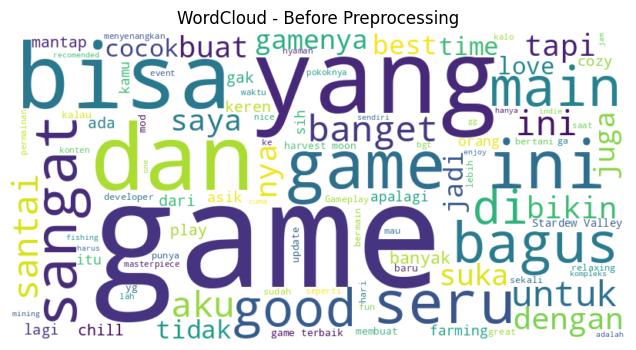

In [38]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

text_before = ' '.join(df['Reviews'].dropna().astype(str))
wordcloud_before = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(text_before)

plt.figure(figsize=(10, 4))
plt.imshow(wordcloud_before, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud - Before Preprocessing')
plt.show()

Pada bagian ini kita membuat WordCloud untuk melihat kata-kata yang paling sering muncul dalam review Stardew Valley. Semakin besar ukuran suatu kata pada WordCloud, semakin sering kata tersebut muncul dalam data review. Visualisasi ini digunakan untuk melihat gambaran umum isi review sebelum dilakukan preprocessing.

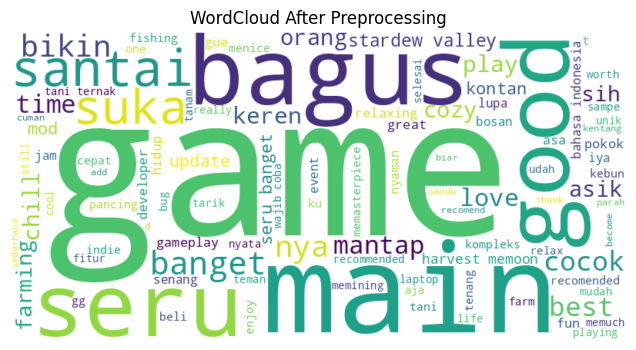

In [39]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# ngegabungin seluruh teks hasil preprocessing
prepro_text = df.loc[:, df.columns == 'prepro'].iloc[:, 0]
text_after = ' '.join(prepro_text.dropna().astype(str))
wordcloud_after = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(text_after)

plt.figure(figsize=(10, 4))
plt.imshow(wordcloud_after, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud After Preprocessing')
plt.show()

Pada bagian ini kita membuat WordCloud setelah preprocessing untuk melihat kata-kata yang masih muncul setelah teks dibersihkan. Visualisasi ini dapat digunakan untuk melihat perubahan kata-kata yang muncul sebelum dan setelah preprocessing.

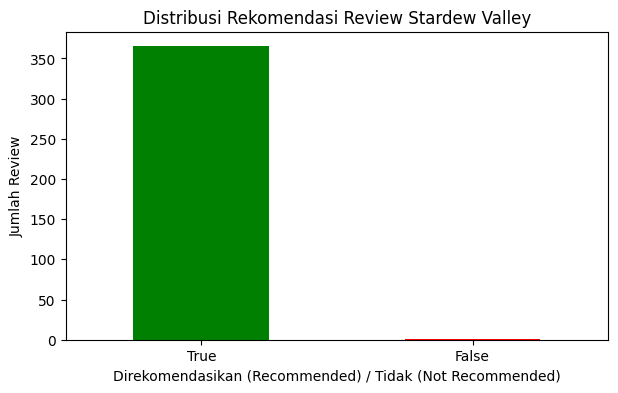

In [40]:
plt.figure(figsize=(7, 4))
df['Voted_up'].value_counts().plot(kind='bar', color=['green', 'red'])
plt.title('Distribusi Rekomendasi Review Stardew Valley')
plt.xlabel('Direkomendasikan (Recommended) / Tidak (Not Recommended)')
plt.ylabel('Jumlah Review')
plt.xticks(rotation=0)
plt.show()

Pada bagian ini kita membuat grafik untuk melihat distribusi rekomendasi dari review Stardew Valley berdasarkan kolom Voted_up. "Recommended" menunjukkan review yang direkomendasikan oleh pengguna, sedangkan "Not Recommended" menunjukkan review yang tidak direkomendasikan. Hasilnya kemudian ditampilkan dalam bentuk grafik agar perbandingan jumlah kedua kategori lebih mudah dilihat.

In [41]:
df.to_csv('steam_reviews_preprocessed.csv', index=False)

And the lasttt, pada bagian ini kita menyimpan data hasil preprocessing ke dalam file CSV dengan nama steam_reviews_preprocessed.csv.

## **Tugas 5 - FEATURE ENGINEERING**

In [42]:
import pandas as pd
df = pd.read_csv('steam_reviews_preprocessed.csv')
df.columns

Index(['Reviews', 'Voted_up', 'rm_html', 'rm_hashtag', 'lower_case', 'rm_url',
       'rm_punc', 'rm_emoji', 'stem', 'prepro'],
      dtype='object')

In [43]:
df_pre = df['prepro']
df_pre.info()

<class 'pandas.core.series.Series'>
RangeIndex: 366 entries, 0 to 365
Series name: prepro
Non-Null Count  Dtype 
--------------  ----- 
363 non-null    object
dtypes: object(1)
memory usage: 3.0+ KB


In [44]:
df_pre = df['prepro'].dropna()
df_pre.info()

<class 'pandas.core.series.Series'>
Index: 363 entries, 0 to 365
Series name: prepro
Non-Null Count  Dtype 
--------------  ----- 
363 non-null    object
dtypes: object(1)
memory usage: 5.7+ KB


Pada tahap ini, library Pandas digunakan untuk membaca dataset steam_reviews_preprocessed.csv dan menyimpannya dalam variabel df. Kolom dataset diperiksa menggunakan df.columns, kemudian kolom prepro dipilih sebagai data teks untuk proses feature engineering. Informasi data diperiksa menggunakan df_pre.info(), yang menunjukkan 366 baris dengan 363 data terisi. Selanjutnya, dropna() digunakan untuk menghapus nilai kosong sehingga tersisa 363 review yang siap diproses.

**Metode 1 : One Hot Encoding**

In [45]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(binary=True)
X = vectorizer.fit_transform(df_pre)
pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

,10,12,1800,2024,2gb,732,abgigail,abigail,achievement,add,...,yaa,yayayaya,years,yes,yi,you,your,yup,zero,zsfasdfsewafdcwaefcdeftcg
0,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
358,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
359,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
360,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
361,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [46]:
df_FE_onehot = pd.DataFrame(X.toarray())

print("Ukuran data:", df_FE_onehot.shape)
print("Jumlah nilai 1:", (df_FE_onehot == 1).sum().sum())
print("Jumlah nilai 0:", (df_FE_onehot == 0).sum().sum())

Ukuran data: (363, 978)
Jumlah nilai 1: 2241
Jumlah nilai 0: 352773


Pada tahap ini, One-Hot Encoding diterapkan menggunakan CountVectorizer(binary=True) untuk mengubah teks menjadi representasi numerik berdasarkan kosakata yang terbentuk. Setiap kolom mewakili satu kata, dengan nilai 1 jika kata muncul dalam review dan 0 jika tidak muncul. Hasilnya disimpan dalam df_FE_onehot. Diperoleh ukuran data (363, 978), dengan 2.241 nilai 1 dan 352.773 nilai 0. Hasil ini menunjukkan bahwa matriks memiliki banyak nilai 0 karena sebagian besar kata tidak muncul pada setiap review.

**Metode 2 : Bag of Words**

In [47]:
vectorizer_bow = CountVectorizer()
X_bow = vectorizer_bow.fit_transform(df_pre)
pd.DataFrame(X_bow.toarray(), columns=vectorizer_bow.get_feature_names_out())

,10,12,1800,2024,2gb,732,abgigail,abigail,achievement,add,...,yaa,yayayaya,years,yes,yi,you,your,yup,zero,zsfasdfsewafdcwaefcdeftcg
0,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
358,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
359,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
360,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
361,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [48]:
df_FE_bow = pd.DataFrame(X_bow.toarray())

print("Ukuran data:", df_FE_bow.shape)
print("Jumlah nilai 0:", (df_FE_bow == 0).sum().sum())
print("Jumlah nilai bukan nol:", (df_FE_bow != 0).sum().sum())

Ukuran data: (363, 978)
Jumlah nilai 0: 352773
Jumlah nilai bukan nol: 2241


Pada tahap ini, Bag of Words digunakan untuk mengubah teks menjadi matriks numerik berdasarkan frekuensi kemunculan kata menggunakan CountVectorizer(). Hasilnya disimpan dalam df_FE_bow, dengan setiap kolom mewakili satu kata dan nilainya menunjukkan frekuensi kata tersebut dalam review. Diperoleh ukuran data (363, 978), dengan 352.773 nilai 0 dan 2.241 nilai bukan nol. Nilai 0 menunjukkan kata tidak muncul, sedangkan nilai bukan nol menunjukkan kata muncul dalam review, baik satu kali maupun lebih.

**Metode 3 : TF-IDF**

In [49]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer_tfidf = TfidfVectorizer()
X_tfidf = vectorizer_tfidf.fit_transform(df_pre)
pd.DataFrame(X_tfidf.toarray(), columns=vectorizer_tfidf.get_feature_names_out())

,10,12,1800,2024,2gb,732,abgigail,abigail,achievement,add,...,yaa,yayayaya,years,yes,yi,you,your,yup,zero,zsfasdfsewafdcwaefcdeftcg
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.198813,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.330145,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
358,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
359,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
360,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
361,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [50]:
df_FE_tfidf = pd.DataFrame(X_tfidf.toarray(), columns=vectorizer_tfidf.get_feature_names_out())

print("Ukuran data:", df_FE_tfidf.shape)
print("Jumlah nilai 0:", (df_FE_tfidf == 0).sum().sum())
print("Jumlah nilai bukan nol:", (df_FE_tfidf != 0).sum().sum())

Ukuran data: (363, 978)
Jumlah nilai 0: 352773
Jumlah nilai bukan nol: 2241


Pada tahap ini, TF-IDF digunakan untuk memberikan bobot kata berdasarkan frekuensi kemunculannya dalam review dan tingkat kelangkaannya dalam seluruh dokumen menggunakan TfidfVectorizer(). Hasilnya disimpan dalam df_FE_tfidf. Diperoleh ukuran data (363, 978), dengan 352.773 nilai 0 dan 2.241 nilai bukan nol. Nilai 0 menunjukkan kata tidak muncul dalam review, sedangkan nilai bukan nol menunjukkan bobot kata yang dihasilkan melalui perhitungan TF-IDF.

**Tokenize Sentence**

In [51]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk import word_tokenize
from tqdm import tqdm

sentences = [word_tokenize(review.lower()) for review in tqdm(df_pre)]
sentences

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
100%|██████████| 363/363 [00:00<00:00, 8485.01it/s]


[['game',
  'sih',
  'game',
  'nya',
  'fleksibel',
  'main',
  'laptop',
  'kentang',
  'sampe',
  'spek',
  'dewa',
  'tarik',
  'game',
  'cozy',
  'gue',
  'main',
  'sampe',
  'lupa',
  'pas',
  'libur',
  'yaa',
  'saran',
  'sih',
  'update',
  'aja',
  'biar',
  'seru',
  'hehe',
  'd'],
 ['i',
  'really',
  'like',
  'the',
  'game',
  'developers',
  'please',
  'add',
  'indonesian',
  'language',
  'support'],
 ['game', 'refreshing'],
 ['game'],
 ['stress', 'realese'],
 ['good'],
 ['game', 'seru', 'main', 'beli', 'game', 'event', 'diskon', 'summer', 'sale'],
 ['if',
  'you',
  're',
  'looking',
  'for',
  'cozy',
  'game',
  'like',
  'harverst',
  'moon',
  'i',
  'really',
  'suggest',
  'and',
  'recomend',
  'you',
  'to',
  'play',
  'this',
  'stardew',
  'valley',
  'alot',
  'of',
  'things',
  'you',
  'can',
  'do',
  'in',
  'here',
  'not',
  'only',
  'become',
  'a',
  'farmer',
  'there',
  'is',
  'also',
  'a',
  'dungeon',
  'you',
  'can',
  'explore',


Pada tahap ini, tokenisasi dilakukan menggunakan word_tokenize dari library NLTK untuk memecah setiap review menjadi kumpulan kata. Fungsi lower() digunakan untuk mengubah teks menjadi huruf kecil, sedangkan tqdm menampilkan progres proses tokenisasi. Hasilnya disimpan dalam variabel sentences berupa list yang berisi kumpulan kata dari setiap review. Sebanyak 363 review berhasil diproses dan hasil tokenisasi digunakan sebagai input untuk model Word2Vec dan FastText.

**Metode 4  : Word2Vec**

In [52]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 26.5 MB/s eta 0:00:00


In [53]:
import gensim.models

model = gensim.models.Word2Vec(sentences, min_count=1, vector_size=100, window=5, sg=0)

In [54]:
model.save('steam_reviews.w2v')

In [55]:
model = gensim.models.Word2Vec.load('steam_reviews.w2v')

In [56]:
w2v = model.wv
w2v.index_to_key[:10]

['game', 'main', 'seru', 'i', 'bagus', 'this', 'good', 'to', 'banget', 'the']

In [57]:
w2v.vectors.shape, w2v.vector_size

((995, 100), 100)

In [58]:
w2v.similar_by_key('seru')

[('nyaman', 0.4044214189052582),
 ('grafik', 0.2711494565010071),
 ('ram', 0.27077025175094604),
 ('luo', 0.2662174701690674),
 ('tambang', 0.25836142897605896),
 ('valley', 0.2577959895133972),
 ('banget', 0.25551918148994446),
 ('and', 0.2543317675590515),
 ('memasing', 0.24036382138729095),
 ('full', 0.23976460099220276)]

In [59]:
import numpy as np

def get_document_vector(tokens, model):
    valid_vectors = [model.wv[word] for word in tokens if word in model.wv]
    return np.mean(valid_vectors, axis=0)

X_features_w2v = np.array([get_document_vector(doc, model) for doc in sentences])
pd.DataFrame(X_features_w2v)

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
0,-0.001233,-0.000041,0.000751,0.000576,-0.000484,-0.003144,0.001011,0.004068,0.000826,-0.003287,...,0.002350,0.001467,0.000299,-0.000277,0.003838,0.002310,-0.000266,-0.001526,-0.000634,0.000452
1,-0.004782,0.001272,-0.000606,0.002788,-0.000955,-0.005723,-0.001129,0.005580,-0.002687,-0.002962,...,-0.000833,0.001628,0.001086,0.001301,0.005058,0.004410,-0.001179,-0.003405,-0.000295,0.003288
2,-0.005468,-0.001263,0.001213,0.000902,-0.008618,-0.009337,0.002579,0.012484,-0.005286,-0.007238,...,0.001782,-0.002488,0.003550,0.004954,0.007068,0.002790,-0.004951,-0.002586,-0.000028,0.007203
3,-0.002797,0.003006,0.006044,0.009744,-0.008859,-0.011617,0.008468,0.016448,-0.005921,-0.005639,...,0.004366,0.002241,0.002142,0.000083,0.014980,0.008666,-0.007253,-0.009963,0.004074,0.005026
4,0.001478,-0.007374,-0.008201,0.006394,0.004478,-0.001086,0.003994,-0.003329,-0.000048,0.003399,...,0.001870,0.000816,0.007479,-0.004195,-0.003911,0.005450,-0.002272,0.004559,0.001195,-0.007236
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
358,-0.000924,0.008148,0.006196,-0.003051,0.003068,0.001978,0.000417,0.004277,-0.003725,-0.000325,...,0.001057,-0.000316,-0.008075,-0.000865,0.003084,0.007528,0.000858,-0.002313,0.003510,0.001296
359,-0.002920,0.001192,0.001825,-0.000438,-0.000765,-0.004463,0.001352,0.000637,0.000562,-0.004937,...,0.000228,0.000090,-0.002663,-0.003518,0.000411,0.005035,0.001966,-0.000556,0.001208,-0.002283
360,-0.002511,-0.003779,0.009036,-0.002458,-0.003866,0.006186,0.005929,0.002193,-0.000799,-0.005943,...,0.003426,-0.007684,0.005579,0.004910,0.007184,-0.005859,-0.005464,-0.003086,0.001126,0.008210
361,-0.008416,-0.000451,0.004882,0.004313,0.002177,-0.001442,-0.002077,0.001522,0.002346,0.001090,...,0.004611,0.002499,0.000118,-0.001563,-0.003582,-0.001408,0.002482,-0.002485,-0.001935,-0.004996


In [60]:
df_FE_w2v = pd.DataFrame(X_features_w2v)

print("Ukuran data:", df_FE_w2v.shape)
print("Jumlah nilai 0:", (df_FE_w2v == 0).sum().sum())
print("Jumlah nilai bukan 0:", (df_FE_w2v != 0).sum().sum())

Ukuran data: (363, 100)
Jumlah nilai 0: 0
Jumlah nilai bukan 0: 36300


In [61]:
!pip install umap-learn

In [62]:
from umap import UMAP
import plotly.express as px

X_umap = UMAP().fit_transform(w2v.vectors)

df2 = pd.DataFrame(X_umap, columns=['umap1', 'umap2'])
df2['word'] = w2v.index_to_key

fig = px.scatter(df2, x='umap1', y='umap2', text='word')
fig.update_traces(textposition='top center')
fig.update_layout(height=800, title_text='Word2Vec Visualization - Steam Reviews')
fig.show()

Pada tahap ini, Word2Vec digunakan untuk mempelajari representasi vektor kata berdasarkan konteksnya dalam review. Model dibuat menggunakan Word2Vec() dengan parameter min_count=1, vector_size=100, window=5, dan sg=0 (arsitektur CBOW), kemudian disimpan dalam file steam_reviews.w2v. Model menghasilkan 995 kata dalam kosakata. Fungsi get_document_vector() menghitung rata-rata vektor kata untuk setiap review dan menyimpannya dalam X_features_w2v, sehingga diperoleh matriks berukuran (363, 100) dengan 0 nilai nol dan 36.300 nilai bukan nol. Selanjutnya, UMAP mereduksi vektor kata menjadi dua dimensi, lalu Plotly menampilkannya dalam scatter plot untuk melihat persebaran dan kedekatan antarkata.

**Metode 5 : FastText Model**

In [63]:
model_fasttext = gensim.models.FastText(sentences, min_count=1,
                                        vector_size=100, window=5,
                                        min_n=3, max_n=6,
                                        sg=1, epochs=10)

In [64]:
model_fasttext.save('steam_reviews.fasttext')

In [65]:
model_fasttext = gensim.models.FastText.load('steam_reviews.fasttext')

In [66]:
fastext = model_fasttext.wv
fastext.index_to_key[:10]

['game', 'main', 'seru', 'i', 'bagus', 'this', 'good', 'to', 'banget', 'the']

In [67]:
fastext.vectors.shape

(995, 100)

In [68]:
fastext.similar_by_key('seru')

[('covering', 0.9998963475227356),
 ('indonesi', 0.9998915195465088),
 ('kering', 0.9998879432678223),
 ('pressuring', 0.9998835325241089),
 ('playing', 0.9998831748962402),
 ('dating', 0.9998828768730164),
 ('memasing', 0.9998823404312134),
 ('saing', 0.9998822212219238),
 ('anjing', 0.9998818635940552),
 ('starting', 0.9998817443847656)]

In [69]:
X_features_fasttext = np.array([get_document_vector(doc, model_fasttext) for doc in sentences])
pd.DataFrame(X_features_fasttext)

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
0,-0.035595,0.022674,-0.132659,-0.003213,0.079870,-0.126583,0.055403,0.165070,-0.000278,0.072211,...,-0.146673,0.054774,-0.014464,0.056239,-0.116102,0.055262,-0.144943,-0.188506,-0.085494,0.138448
1,-0.034043,0.022625,-0.131745,-0.003957,0.078520,-0.126662,0.054751,0.163868,-0.000306,0.071041,...,-0.146395,0.054922,-0.013524,0.055201,-0.114036,0.054497,-0.142803,-0.186965,-0.084111,0.135717
2,-0.045082,0.030724,-0.171769,-0.003298,0.100858,-0.162634,0.068671,0.210267,-0.000664,0.093005,...,-0.187488,0.069579,-0.016243,0.071642,-0.150113,0.071159,-0.185093,-0.242055,-0.106706,0.177418
3,-0.056513,0.039356,-0.217727,-0.004908,0.129264,-0.206220,0.087833,0.266988,-0.001073,0.117057,...,-0.237528,0.090106,-0.022312,0.090228,-0.190607,0.089374,-0.234261,-0.308150,-0.134988,0.226767
4,-0.023070,0.014301,-0.088416,-0.002878,0.052048,-0.085819,0.034963,0.109928,-0.000007,0.048664,...,-0.097977,0.037023,-0.007877,0.036740,-0.076877,0.036452,-0.096427,-0.124711,-0.057376,0.089601
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
358,-0.030202,0.019615,-0.107531,-0.003762,0.066954,-0.105084,0.045691,0.135832,-0.002114,0.058232,...,-0.121440,0.042887,-0.013598,0.047281,-0.093434,0.044980,-0.117836,-0.153884,-0.066015,0.112659
359,-0.027228,0.016945,-0.098070,-0.002823,0.060389,-0.095220,0.041103,0.125442,0.001748,0.053132,...,-0.111064,0.040532,-0.011102,0.041197,-0.086719,0.042126,-0.107484,-0.141132,-0.064571,0.099522
360,-0.032855,0.020486,-0.115113,-0.001072,0.066664,-0.109761,0.049108,0.139934,-0.000045,0.062400,...,-0.129086,0.048658,-0.010981,0.047276,-0.099292,0.047392,-0.123472,-0.162599,-0.075587,0.119250
361,-0.036255,0.022936,-0.134171,-0.003601,0.082860,-0.129226,0.055654,0.169062,-0.000450,0.073200,...,-0.150037,0.055878,-0.013958,0.057175,-0.120234,0.056388,-0.148537,-0.192205,-0.086982,0.140698


In [70]:
df_FE_fasttext = pd.DataFrame(X_features_fasttext)

print("Ukuran data:", df_FE_fasttext.shape)
print("Jumlah nilai 0:", (df_FE_fasttext == 0).sum().sum())
print("Jumlah nilai bukan 0:", (df_FE_fasttext != 0).sum().sum())

Ukuran data: (363, 100)
Jumlah nilai 0: 0
Jumlah nilai bukan 0: 36300


In [71]:
X_umap_ft = UMAP().fit_transform(fastext.vectors)

df3 = pd.DataFrame(X_umap_ft, columns=['umap1', 'umap2'])
df3['word'] = fastext.index_to_key

fig = px.scatter(df3, x='umap1', y='umap2', text='word')
fig.update_traces(textposition='top center')
fig.update_layout(height=800, title_text='FastText Visualization - Steam Reviews')
fig.show()

Pada tahap ini, FastText digunakan untuk mempelajari representasi vektor kata dengan mempertimbangkan informasi subkata (character n-grams). Model dibuat menggunakan FastText() dengan parameter min_count=1, vector_size=100, window=5, min_n=3, max_n=6, sg=1, dan epochs=10, sehingga menggunakan arsitektur Skip-gram dengan subkata sepanjang 3–6 karakter. Model disimpan dan dimuat kembali melalui file steam_reviews.fasttext, dengan kosakata sebanyak 995 kata dan dimensi vektor 100. Fungsi get_document_vector() kemudian menghitung rata-rata vektor kata pada setiap review dan menyimpannya dalam X_features_fasttext, menghasilkan matriks berukuran (363, 100). Selanjutnya, UMAP mereduksi vektor kata menjadi dua dimensi yang disimpan dalam df3, lalu Plotly menampilkannya dalam scatter plot untuk mengamati persebaran dan kedekatan antarkata.